# The Laplace Resonance of GJ 876

*Matthew Payne*

Jupiter's moons Io, Europa and Ganymede are locked together: for every orbit of Ganymede, Europa orbits twice and Io four times, and the combination $\lambda_{\rm Io} - 3\lambda_{\rm Europa} + 2\lambda_{\rm Ganymede}$ of their mean longitudes stays fixed at 180°. This three-body "Laplace resonance" was for long the only one known. The M dwarf GJ 876 was the first exoplanetary system found in such a configuration (Rivera et al. 2010): its planets c, b and e orbit in about 30, 61 and 124 days, close to 1:2:4.

This notebook integrates the orbital solution of

> B. E. Nelson, P. M. Robertson, M. J. Payne, S. M. Pritchard, K. M. Deck & E. B. Ford (2016), *An empirically derived three-dimensional Laplace resonance in the Gliese 876 planetary system*, MNRAS **455**, 2484. [ADS](https://ui.adsabs.harvard.edu/abs/2016MNRAS.455.2484N/abstract) · [arXiv:1504.07995](https://arxiv.org/abs/1504.07995)

(N16), who fitted twenty years of radial velocities from five spectrographs with $N$-body models and differential-evolution MCMC (see the companion notebook on Nelson, Ford & Payne 2014).

We will:

1. Set up N16's coplanar four-planet solution and integrate it for 60 years.
2. Watch the two-body resonant angles of the c–b pair, and the Laplace angle of the c–b–e trio.
3. Measure their libration amplitudes as N16 do, and compare with their Table 6.
4. Propagate N16's uncertainties to the Laplace angle's amplitude.
5. See how the Laplace angle responds to the outer planet's mass.

**Requirements:** `numpy`, `matplotlib` and `rebound`. **Run time:** about a minute on 12 cores.

In [1]:
import os
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np

import gj876    # helper module in this folder: N16's solution, integration and resonant angles

NPROC = os.cpu_count()

## 1. N16's coplanar solution

N16 fix the star's mass at $0.37\,M_\odot$ (von Braun et al. 2014) and fit each planet's mass, semi-major axis, eccentricity, argument of pericentre and mean anomaly, at the epoch of the first observation, in Jacobi coordinates, with all four planets in one plane inclined at 53.19° to the sky (their Table 3). We start from the median of each parameter. The medians of separate marginal distributions need not form one good solution, so we check that this one is stable and resonant, and in Section 4 we look at the spread.

In [2]:
print("planet   mass (M_Earth)   a (au)      e       omega (deg)   M (deg)")
for k in gj876.ORDER:
    p = gj876.medians()[k]
    print(f"   {k}      {p['m']:7.2f}      {p['a']:.6f}   {p['e']:.4f}   {p['omega']:9.2f}   {p['M']:9.2f}")
run = gj876.evolve(gj876.medians(), years=60, n_out=3000)
P = [2 * np.pi * np.sqrt(a**3 / (gj876.G * gj876.M_STAR)) for a in run["a"][0]]
print(f"\nPeriods (days): " + ", ".join(f"{k} {p:.2f}" for k, p in zip(gj876.ORDER, P)))
print(f"Period ratios: b/c = {P[2] / P[1]:.3f}, e/b = {P[3] / P[2]:.3f}; stable for 60 years: {run['stable']}")

planet   mass (M_Earth)   a (au)      e       omega (deg)   M (deg)
   d         7.49      0.021839   0.1190     -140.90      301.87
   c       266.20      0.135989   0.2531      115.96     -220.68
   b       845.30      0.218585   0.0368      110.80     -285.38
   e        16.58      0.351400   0.0310      129.56     -175.89



Periods (days): d 1.94, c 30.11, b 61.37, e 125.08
Period ratios: b/c = 2.038, e/b = 2.038; stable for 60 years: True


## 2. Resonant angles

For two planets near a 2:1 resonance, the *resonant angles* $\phi = \lambda_{\rm inner} - 2\lambda_{\rm outer} + \varpi$ combine mean longitudes $\lambda$ with a longitude of pericentre $\varpi$ (of either planet). Away from resonance they circulate through all values; in resonance they *librate*, oscillating about a fixed value, so that conjunctions keep happening at the same places in the orbits. The Laplace angle $\phi_L = \lambda_c - 3\lambda_b + 2\lambda_e$ does the same for all three planets at once (N16 Sec. 6).

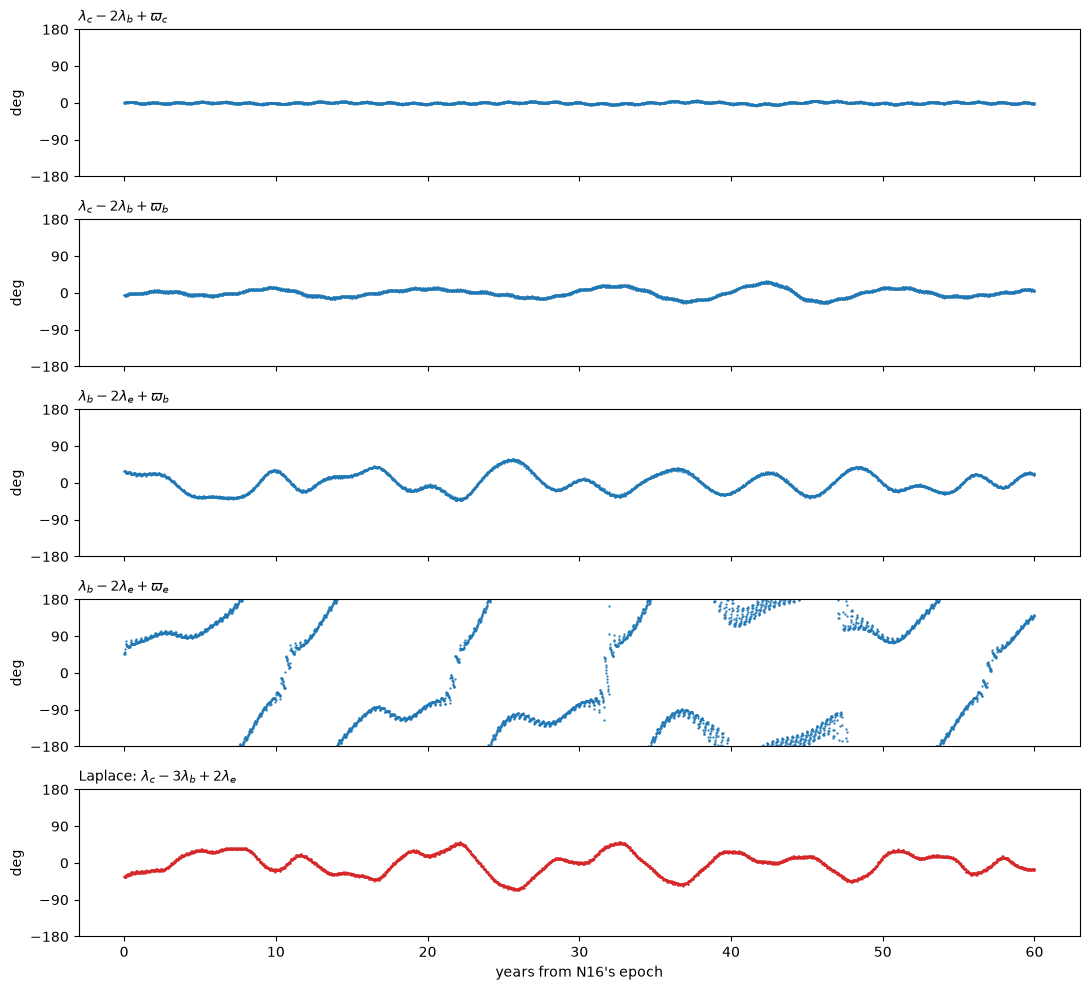

In [3]:
ang = gj876.angles(run)
show = [("phi_cb_c", r"$\lambda_c - 2\lambda_b + \varpi_c$"), ("phi_cb_b", r"$\lambda_c - 2\lambda_b + \varpi_b$"),
        ("phi_be_b", r"$\lambda_b - 2\lambda_e + \varpi_b$"), ("phi_be_e", r"$\lambda_b - 2\lambda_e + \varpi_e$"),
        ("laplace", r"Laplace: $\lambda_c - 3\lambda_b + 2\lambda_e$")]
fig, axs = plt.subplots(len(show), 1, figsize=(11, 10), sharex=True)
for ax, (k, lab) in zip(axs, show):
    ax.plot(run["t"], np.degrees(ang[k]), ".", ms=1.2, color="C3" if k == "laplace" else "C0")
    ax.set(ylim=(-180, 180), yticks=[-180, -90, 0, 90, 180], ylabel="deg")
    ax.set_title(lab, fontsize=10, loc="left")
axs[-1].set_xlabel("years from N16's epoch")
fig.tight_layout()
plt.show()

The c–b angles librate tightly about 0°; for the b–e pair, $\phi^{be}_b$ librates while $\phi^{be}_e$ circulates, as N16 found; and the Laplace angle librates about 0° with a period of several years.

## 3. Libration amplitudes

N16 define the libration amplitude of an angle as $\sqrt2$ times the root-mean-square variation of the angle, an excellent estimate for small sinusoidal librations (their Sec. 6.1). Here are the amplitudes for the median solution next to N16's coplanar values (their Table 8, which gives the median and the 15.9 and 84.1 percentiles of the amplitude over their posterior):

In [4]:
print("angle          this run    N16 (coplanar)")
for k, (med, lo, hi) in gj876.N16_AMPLITUDES.items():
    a = gj876.amplitude(ang[k])
    print(f"{k:12s} {a:8.1f}°    {med:5.1f}° (-{lo}, +{hi})")
print(f"{'phi_be_e':12s} {'circulates' if gj876.amplitude(ang['phi_be_e']) is None else gj876.amplitude(ang['phi_be_e'])}    circulates")

angle          this run    N16 (coplanar)
phi_cb_c          2.9°      4.0° (-1.4, +1.6)
phi_cb_b         14.7°     13.4° (-1.4, +3.0)
dvarpi_cb        16.7°     14.7° (-3.3, +4.0)
phi_be_b         32.9°     31.3° (-8.7, +11.9)
phi_ce_0         77.7°     67.5° (-19.4, +25.4)
laplace          37.3°     33.0° (-9.3, +12.4)
phi_be_e     circulates    circulates


The median solution reproduces N16's picture: every amplitude falls within their 68% range, including the Laplace angle's, 37° against $33^{+12}_{-9}$ degrees, and $\phi^{be}_e$ circulates, as they found.

## 4. How well is the Laplace amplitude known?

N16 found the Laplace angle's amplitude to be $33^{+12}_{-9}$ degrees for the coplanar model. Their posterior sample is not public in this form, so we approximate it: we draw the parameters of planets c, b and e independently from N16's marginal uncertainties and integrate each draw. Because real posteriors are correlated, independent draws are a cruder, wider approximation, and some of them will not even be stable.

120 of 120 draws stable for 60 years; the Laplace angle librates in 95 of them
Laplace libration amplitude: 58 (-20, +30) degrees; N16: 33 (-9, +12)


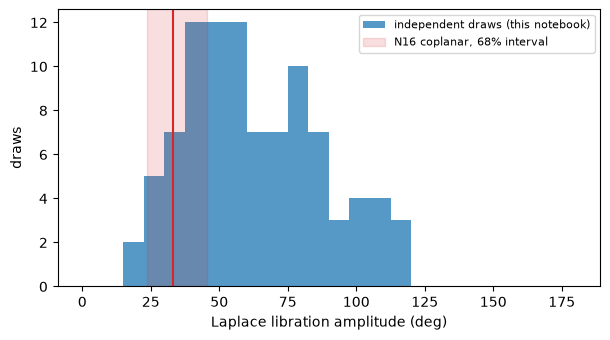

In [5]:
N_DRAWS = 120
with Pool(NPROC) as pool:
    res = pool.map(gj876.draw_job, [(1000 + k, 60.0) for k in range(N_DRAWS)], chunksize=2)
ok = [r for r in res if r is not None]
lap = np.array([r["laplace"] for r in ok if r["laplace"] is not None])
print(f"{len(ok)} of {N_DRAWS} draws stable for 60 years; the Laplace angle librates in {lap.size} of them")
q16, q50, q84 = np.percentile(lap, [15.9, 50, 84.1])
print(f"Laplace libration amplitude: {q50:.0f} (-{q50 - q16:.0f}, +{q84 - q50:.0f}) degrees; N16: 33 (-9, +12)")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(lap, bins=np.arange(0, 181, 7.5), color="C0", alpha=0.75, label="independent draws (this notebook)")
ax.axvspan(33.0 - 9.3, 33.0 + 12.4, color="C3", alpha=0.15, label="N16 coplanar, 68% interval")
ax.axvline(33.0, color="C3")
ax.set(xlabel="Laplace libration amplitude (deg)", ylabel="draws")
ax.legend(fontsize=8)
plt.show()

All the draws survive 60 years, but the Laplace angle circulates in about a fifth of them, and where it librates the amplitudes are larger and more spread out than N16's. That is the price of ignoring the correlations between parameters: N16's posterior holds only combinations of parameters that fit the data together, and those keep the planets close to exact resonance. The point stands that the amplitude is moderate, neither close to zero (which would suggest strong damping, for example during migration in a disc) nor so large that the angle circulates, as N16 discuss.

## 5. How much does planet e's mass matter?

Planet e is by far the lightest of the three, about 17 Earth masses against 266 and 845. Changing its mass, with everything else fixed, shows how sensitive the Laplace configuration is to it:

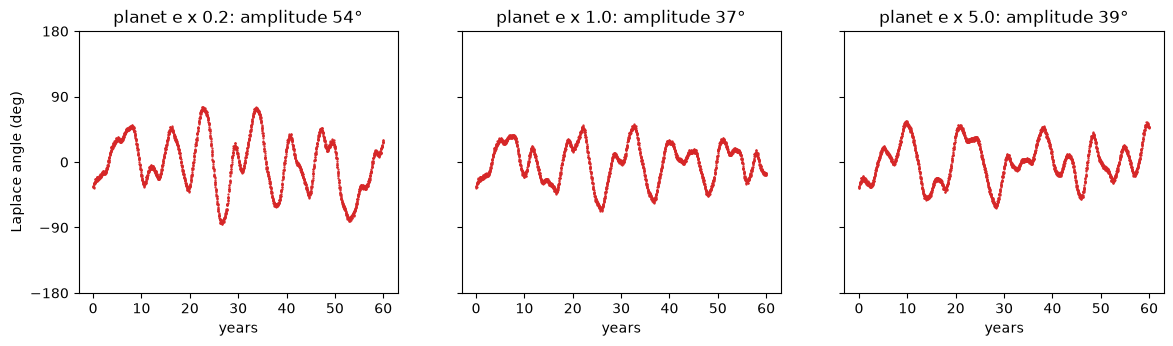

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
for ax, f in zip(axs, [0.2, 1.0, 5.0]):
    r = gj876.evolve(gj876.medians(), years=60, n_out=3000, mass_scale={"e": f})
    a = gj876.angles(r)["laplace"]
    amp = gj876.amplitude(a)
    ax.plot(r["t"], np.degrees(a), ".", ms=1.2, color="C3")
    ax.set(title=f"planet e x {f}: " + ("circulates" if amp is None else f"amplitude {amp:.0f}°") + ("" if r["stable"] else " (unstable)"),
           xlabel="years", ylim=(-180, 180), yticks=[-180, -90, 0, 90, 180])
axs[0].set_ylabel("Laplace angle (deg)")
plt.show()

The Laplace angle keeps librating whether planet e is five times lighter or five times heavier; its amplitude changes, from 37° to 54° with a lighter planet e, but the configuration persists over these 60 years. The libration of the three-body angle follows from the two 2:1 resonances it combines, $\phi_L = \phi^{cb}_c - \phi^{be}_b + (\varpi_b - \varpi_c)$ in terms of angles we measured above, each of which librates.

## Summary

* Integrating N16's coplanar orbital solution for GJ 876 with REBOUND reproduces their resonant structure: the c–b pair deep in the 2:1 resonance, the b–e pair in it more loosely, and the Laplace angle $\lambda_c - 3\lambda_b + 2\lambda_e$ librating about 0°.
* Measured as N16 do, the libration amplitudes of the median solution all fall within their uncertainties; the Laplace angle's is 37°, against their $33^{+12}_{-9}$ degrees.
* Drawing parameters independently from N16's marginal uncertainties gives larger, more scattered amplitudes, a reminder that a posterior's correlations matter for derived quantities like these.
* The Laplace configuration persists over a wide range of masses for the outer planet, though with different amplitudes.

## Going further

* **Three dimensions.** N16's 3D fits allow each planet its own inclination and node; they find the planets must be nearly coplanar (mutual inclinations below about 3° and 8° when long-term stability is required), with a larger Laplace amplitude, $51^{+8}_{-10}$ degrees. Add inclinations to `gj876.make_sim` and explore.
* **Chaos.** Rivera et al. (2010) noted that the Laplace angle evolves chaotically. Integrate two nearly identical solutions for a few centuries and watch them separate.
* **Planet d.** The innermost planet, d, orbits in under two days and takes no part in the resonance; try removing it.

## References

* Nelson, B. E., Robertson, P. M., Payne, M. J., Pritchard, S. M., Deck, K. M. & Ford, E. B. 2016, *An empirically derived three-dimensional Laplace resonance in the Gliese 876 planetary system*, MNRAS 455, 2484. [ADS](https://ui.adsabs.harvard.edu/abs/2016MNRAS.455.2484N/abstract)
* Rein, H. & Spiegel, D. S. 2015, *IAS15: a fast, adaptive, high-order integrator for gravitational dynamics, accurate to machine precision over a billion orbits*, MNRAS 446, 1424. [ADS](https://ui.adsabs.harvard.edu/abs/2015MNRAS.446.1424R/abstract)
* Rivera, E. J., Laughlin, G., Butler, R. P. et al. 2010, *The Lick-Carnegie Exoplanet Survey: A Uranus-Mass Fourth Planet for GJ 876 in an Extrasolar Laplace Configuration*, ApJ 719, 890. [ADS](https://ui.adsabs.harvard.edu/abs/2010ApJ...719..890R/abstract)
* von Braun, K., Boyajian, T. S., van Belle, G. T. et al. 2014, *Stellar diameters and temperatures - V. 11 newly characterized exoplanet host stars*, MNRAS 438, 2413. [ADS](https://ui.adsabs.harvard.edu/abs/2014MNRAS.438.2413V/abstract)